# Assignment: Exploratory Data Analysis and Visualization
**Dataset:** Telecom Market in Bangladesh (Monthly Subscribers, 2008–2015)

## Task 1: Explain Your Dataset

- **Dataset name:** Telecom Market in Bangladesh – Monthly Subscribers
- **Source:** Internal GP (Grameenphone) market model, originally based on BTRC (Bangladesh Telecommunication Regulatory Commission) operator data.
- **Purpose:** Track monthly subscriber growth and market share of all major mobile operators in Bangladesh to understand competition and sector trends.
- **Rows and columns:** After tidying, the dataset has **576 rows** (6 operators × 96 months) and **7 columns**.
- **Description of features:**
  - `Operator` – mobile operator name (Grameenphone, Banglalink, Robi, Airtel, Citycell, Teletalk)
  - `Date` – month/year of observation
  - `Year` – year (2008–2015)
  - `Month` – calendar month name
  - `Subscribers_Mn` – number of subscribers in millions
  - `MoM_Growth_%` – month-over-month subscriber growth rate
  - `Market_Share_%` – operator's share of total sector subscribers

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('telecom_clean.csv', parse_dates=['Date'])
print('Shape:', df.shape)
df.head()

Shape: (576, 7)


,Operator,Date,Year,Month,Subscribers_Mn,MoM_Growth_%,Market_Share_%
0,Airtel,2008-01-01,2008,January,2.37,NaN,6.505627
1,Airtel,2008-02-01,2008,February,2.60,9.704641,6.924101
2,Airtel,2008-03-01,2008,March,2.79,7.307692,7.166709
3,Airtel,2008-04-01,2008,April,2.93,5.017921,7.265063
4,Airtel,2008-05-01,2008,May,3.13,6.825939,7.445290


## Task 3: Identify Categorical and Numerical Columns

In [2]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()
print('Numerical columns:', num_cols)
print('Categorical columns:', cat_cols)

Numerical columns: ['Year', 'Subscribers_Mn', 'MoM_Growth_%', 'Market_Share_%']
Categorical columns: ['Operator', 'Month']


C:\Users\Asir\AppData\Local\Temp\ipykernel_7628\146132333.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()


Exploratory Data Analysis (EDA)

### 3.1 Checking missing values
**Why:** Missing values can distort statistics and break model training.

In [3]:
df.isnull().sum()

Operator          0
Date              0
Year              0
Month             0
Subscribers_Mn    0
MoM_Growth_%      6
Market_Share_%    0
dtype: int64

### 3.2 Checking duplicate records
**Why:** Duplicates inflate counts and bias means.

In [4]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


### 3.3 Statistical summary
**Why:** Reveals central tendency, spread, and extreme values at a glance.

In [5]:
df.describe().round(2)

,Date,Year,Subscribers_Mn,MoM_Growth_%,Market_Share_%
count,576,576.00,576.00,570.00,576.00
mean,2011-12-16 11:00:00,2011.50,14.03,1.23,16.67
min,2008-01-01 00:00:00,2008.00,0.84,-41.71,0.78
25%,2009-12-24 06:00:00,2009.75,1.91,0.14,3.12
50%,2011-12-16 12:00:00,2011.50,8.34,1.06,12.74
75%,2013-12-08 18:00:00,2013.25,23.96,2.29,25.65
max,2015-12-01 00:00:00,2015.00,56.54,20.44,47.80
std,NaN,2.29,14.11,3.36,14.89


### 3.4 Data distribution
**Why:** Tells us whether features are normal, skewed, or multi-modal.

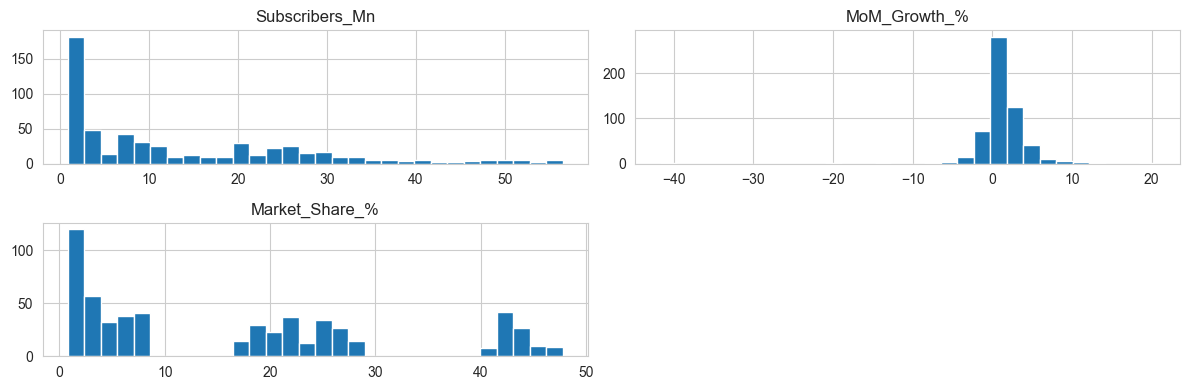

In [6]:
df[['Subscribers_Mn', 'MoM_Growth_%', 'Market_Share_%']].hist(bins=30, figsize=(12,4))
plt.tight_layout()
plt.show()

### 3.5 Correlations
**Why:** Identifies linear relationships between numerical variables.

In [7]:
corr = df[['Subscribers_Mn', 'MoM_Growth_%', 'Market_Share_%']].corr()
corr.round(2)

,Subscribers_Mn,MoM_Growth_%,Market_Share_%
Subscribers_Mn,1.00,0.01,0.88
MoM_Growth_%,0.01,1.00,0.07
Market_Share_%,0.88,0.07,1.00


### 3.6 Outlier detection
**Why:** Outliers can skew averages and signal anomalies worth investigating.

In [8]:
q1, q3 = df['MoM_Growth_%'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df['MoM_Growth_%'] < q1 - 1.5*iqr) | (df['MoM_Growth_%'] > q3 + 1.5*iqr)]
print('Number of MoM growth outliers:', len(outliers))

Number of MoM growth outliers: 51


## Task 4: Data Visualization

### 4.1 Subscriber growth over time by operator

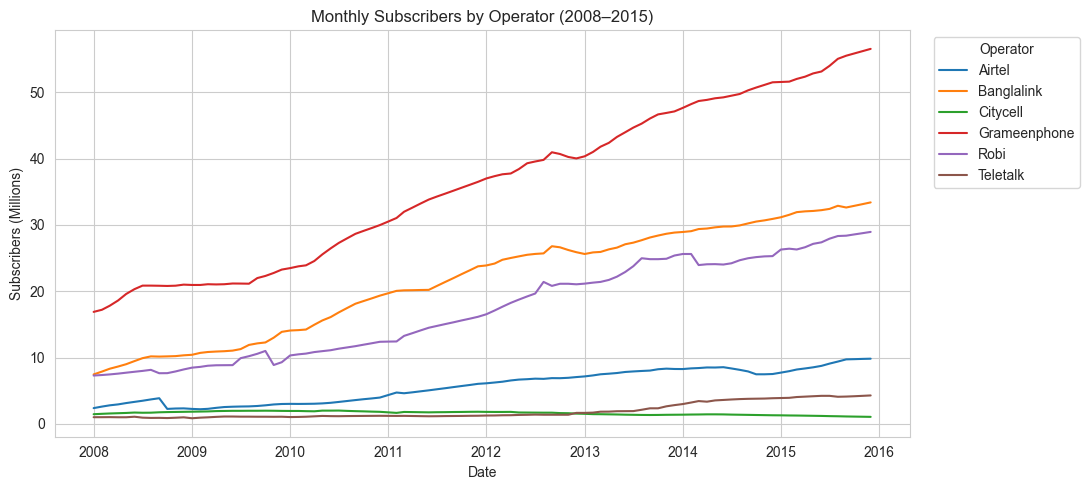

In [9]:
plt.figure(figsize=(11, 5))
sns.lineplot(data=df, x='Date', y='Subscribers_Mn', hue='Operator')
plt.title('Monthly Subscribers by Operator (2008–2015)')
plt.xlabel('Date')
plt.ylabel('Subscribers (Millions)')
plt.legend(title='Operator', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 4.2 Distribution of subscribers per operator (boxplot)

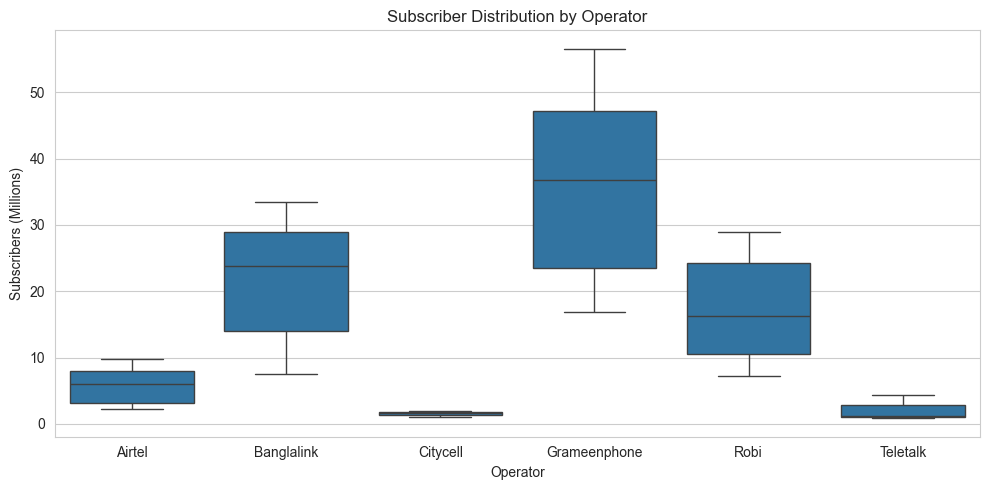

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Operator', y='Subscribers_Mn')
plt.title('Subscriber Distribution by Operator')
plt.xlabel('Operator')
plt.ylabel('Subscribers (Millions)')
plt.tight_layout()
plt.show()

### 4.3 Average market share per operator (bar chart)

C:\Users\Asir\AppData\Local\Temp\ipykernel_7628\3919199062.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=share.index, y=share.values, palette='viridis')


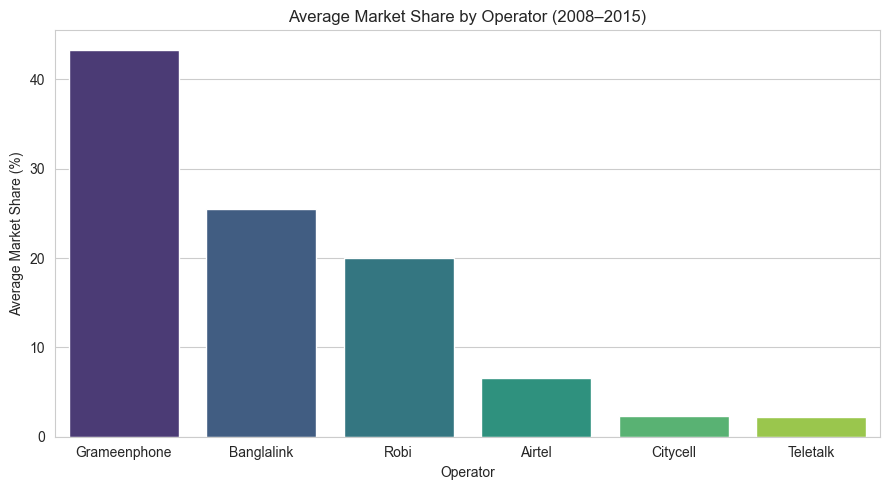

In [11]:
share = df.groupby('Operator')['Market_Share_%'].mean().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=share.index, y=share.values, palette='viridis')
plt.title('Average Market Share by Operator (2008–2015)')
plt.xlabel('Operator')
plt.ylabel('Average Market Share (%)')
plt.tight_layout()
plt.show()

### 4.4 Correlation heatmap

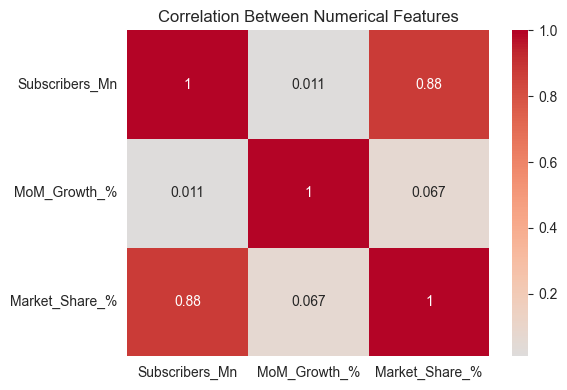

In [12]:
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Between Numerical Features')
plt.tight_layout()
plt.show()

### 4.5 Yearly sector total

C:\Users\Asir\AppData\Local\Temp\ipykernel_7628\2983713594.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=yearly.index, y=yearly.values, palette='Blues_d')


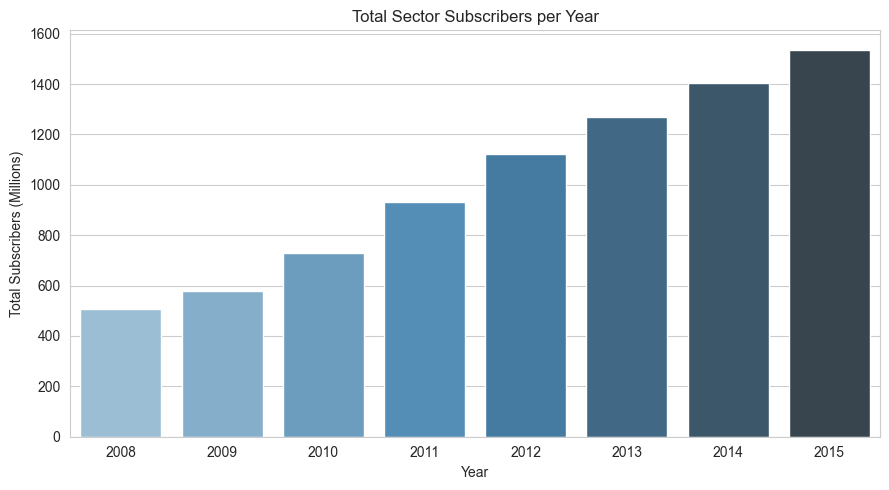

In [13]:
yearly = df.groupby('Year')['Subscribers_Mn'].sum()
plt.figure(figsize=(9, 5))
sns.barplot(x=yearly.index, y=yearly.values, palette='Blues_d')
plt.title('Total Sector Subscribers per Year')
plt.xlabel('Year')
plt.ylabel('Total Subscribers (Millions)')
plt.tight_layout()
plt.show()

## Task 5: Insights from the Visualizations

**From the time-series line plot (4.1):**
- Grameenphone leads the market throughout the entire 2008–2015 period and grew from ~17M to ~56M subscribers.
- Banglalink and Robi grew steadily and emerged as clear #2 and #3 players.
- Citycell consistently declined, reflecting its loss of competitiveness.
- Teletalk remained the smallest operator with slow growth.

**From the boxplot (4.2):**
- Grameenphone shows the widest spread, indicating massive growth over the period.
- Citycell and Teletalk have narrow distributions — their subscriber base barely changed.

**From the market-share bar chart (4.3):**
- Grameenphone dominates with around 42% average market share.
- The top 3 operators (Grameenphone, Banglalink, Robi) together hold roughly 90% of the market — a clear oligopoly.

**From the correlation heatmap (4.4):**
- Subscribers and market share are strongly positively correlated (as expected).
- MoM growth has weak correlation with absolute subscribers — growth rate is not just driven by size.

**From the yearly bar chart (4.5):**
- The sector grew almost every year, with the total subscriber base nearly tripling between 2008 and 2015.
- This indicates a rapidly expanding telecom market driven by rising mobile penetration in Bangladesh.